# A Recurrent Network for Next-Word Prediction

Open in [Google Colab](https://colab.research.google.com/github/febse/ta2025/blob/main/03-12-RNN-Next-Word-Prediction.ipynb)

In the [bigram chapter](03-02-ANN-Bigram-Motivation.ipynb) we predicted the next word of *Alice's Adventures in Wonderland* from **one** previous word. A single word is a poor summary of what has been said: after "the" almost anything can follow, but after "the queen of" the next word is much more predictable. A language model should use the whole preceding sequence,

$$
P(w_{t+1} \mid w_1, w_2, \ldots, w_t),
$$

but a feed-forward network needs a fixed number of inputs, and a sequence can have any length. A **recurrent neural network (RNN)** [@ELMAN1990FindingStructureTime] solves this by reading the words one at a time and carrying a **hidden state** $h_t$ (a vector of $k$ numbers) that summarizes everything read so far.

In this chapter we

1. build the recurrent cell by hand and check it against PyTorch,
2. train a small network to predict the next word of *Alice in Wonderland*,
3. compare it with the unigram and bigram models, and
4. use it for next-word suggestions, text generation and for scoring how natural a sentence is.

We keep the notation of the previous chapters: row vectors, weights that multiply from the right, $h$ for net values and $z$ for activations. Here the activation of the recurrent layer is the hidden state $h_t$.

## The Recurrent Cell

Each word $w_t$ is first mapped to an **embedding** $x_t$ (a $1 \times e$ row vector, a row of an embedding matrix, see the [Word2Vec chapter](03-09-Word2Vec.ipynb)). The hidden state is updated by

:::{.ex-class}
$$
h_t = \tanh\left( x_t W_x + h_{t-1} W_h + b_h \right), \qquad h_0 = \mathbf{0},
$$
:::

where $W_x$ is $e \times k$, $W_h$ is $k \times k$ and $b_h$ is a bias. The new state is a non-linear mix of the current word and the previous state. The **same** $W_x$, $W_h$, $b_h$ are used at every time step (weight sharing over time, in the same way as a convolution shares its kernel over positions). After the last word $w_t$ a linear layer turns the final state into one logit per word of the vocabulary and the softmax gives the probabilities of the next word:

:::{.ex-class}
$$
P(w_{t+1} = j \mid w_1, \ldots, w_t) = \text{softmax}\left( h_t W_o + b_o \right)_j .
$$
:::

The network is trained with the cross-entropy loss, exactly as in the [multi-class chapter](03-07-ANN-Multiclass-Classification.ipynb): the target is the index of the true next word. Written out for three words, the network is a feed-forward network with three layers that share their weights:

$$
h_1 = \tanh(x_1 W_x + b_h), \quad
h_2 = \tanh(x_2 W_x + h_1 W_h + b_h), \quad
h_3 = \tanh(x_3 W_x + h_2 W_h + b_h)
$$

Gradients flow back through all time steps ("backpropagation through time"), which PyTorch does automatically.

## The Data

The text is Project Gutenberg eBook #11 (<https://www.gutenberg.org/ebooks/11>, public domain), which is also available in `nltk`. We tokenize in the same way as in the bigram chapter (lower-case words) and keep the words that occur at least twice; all other words become the token `<unk>`.

The text is split **chronologically**: the first 80% of the book is used for training, the next 10% for validation and the last 10% for testing. A random split of overlapping windows would leak the test text into the training data.

In [1]:
import re
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import nltk
import torch
import torch.nn as nn
from nltk.corpus import gutenberg

nltk.download("gutenberg", quiet=True)
tokens = re.findall(r"[a-z']+", gutenberg.raw("carroll-alice.txt").lower())

counts = Counter(tokens)
vocabulary = ["<unk>"] + [word for word, n in counts.most_common() if n >= 2]
word_to_id = {word: i for i, word in enumerate(vocabulary)}
VOCAB_SIZE = len(vocabulary)
UNK = word_to_id["<unk>"]

def encode(words):
    return [word_to_id.get(word, UNK) for word in words]

ids = np.array(encode(tokens))
n_train, n_val = int(0.8 * len(ids)), int(0.9 * len(ids))
segments = {"train": ids[:n_train], "val": ids[n_train:n_val], "test": ids[n_val:]}

print("tokens:", len(tokens), " vocabulary size:", VOCAB_SIZE)
print("share of <unk> tokens:", round((ids == UNK).mean(), 3))
print({name: len(segment) for name, segment in segments.items()})

tokens: 27802  vocabulary size: 1585
share of <unk> tokens: 0.046
{'train': 22241, 'val': 2780, 'test': 2781}


### Training Examples

An example consists of a **context** of $L$ consecutive words and the **target**, the word that follows. We slide a window of length $L = 8$ over each segment (the windows of the three segments never overlap).

In [2]:
CONTEXT = 8

def make_windows(segment, context=CONTEXT, start=CONTEXT):
    # contexts[i] = the `context` words before position t, targets[i] = the word at position t
    positions = np.arange(start, len(segment))
    contexts = np.stack([segment[t - context:t] for t in positions])
    return torch.tensor(contexts), torch.tensor(segment[positions])

X_train, y_train = make_windows(segments["train"])
X_val, y_val = make_windows(segments["val"])
X_test, y_test = make_windows(segments["test"])

print("contexts:", X_train.shape, X_val.shape, X_test.shape)
for i in (0, 1000):
    print(" ".join(vocabulary[j] for j in X_train[i]), "->", vocabulary[y_train[i]])

contexts: torch.Size([22233, 8]) torch.Size([2772, 8]) torch.Size([2773, 8])
alice's adventures in wonderland by <unk> <unk> chapter -> i
on to her feet in a moment she -> looked


## The Networks

### A Recurrent Cell Written by Hand

The class below implements the equations above with an explicit loop over the time steps. The weights are plain `nn.Parameter`s, so that we can see exactly what is computed.

In [3]:
class ElmanRNN(nn.Module):
    # h_t = tanh(x_t W_x + h_{t-1} W_h + b_h); the logits are computed from the last state
    def __init__(self, vocab_size, embedding_size=32, hidden_size=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_size)
        self.W_x = nn.Parameter(torch.randn(embedding_size, hidden_size) / embedding_size ** 0.5)
        self.W_h = nn.Parameter(torch.randn(hidden_size, hidden_size) / hidden_size ** 0.5)
        self.b_h = nn.Parameter(torch.zeros(hidden_size))
        self.output = nn.Linear(hidden_size, vocab_size)

    def forward(self, word_ids):
        # word_ids: (n, L) integers -> logits (n, vocab_size)
        x = self.embedding(word_ids)                         # (n, L, e)
        h = torch.zeros(word_ids.shape[0], self.W_h.shape[0])
        for t in range(word_ids.shape[1]):
            h = torch.tanh(x[:, t] @ self.W_x + h @ self.W_h + self.b_h)
        return self.output(h)

### The Same Network with `nn.RNN` (and GRU, LSTM)

PyTorch provides the recurrent layer in `nn.RNN` (and the gated variants `nn.GRU` and `nn.LSTM`, which we use below). The class `NextWordNet` wraps any of them: embedding, recurrent layer, dropout (a regularizer that randomly sets 30% of the final state to zero during training) and the linear output layer. The `forward` method uses only the **last** hidden state, because we predict one word after the context.

In [4]:
class NextWordNet(nn.Module):
    def __init__(self, vocab_size, embedding_size=32, hidden_size=128, kind="rnn", dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_size)
        layer = {"rnn": nn.RNN, "gru": nn.GRU, "lstm": nn.LSTM}[kind]
        self.recurrent = layer(embedding_size, hidden_size, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.output = nn.Linear(hidden_size, vocab_size)

    def forward(self, word_ids):
        # word_ids: (n, L); any length L >= 1 works
        states, _ = self.recurrent(self.embedding(word_ids))   # (n, L, hidden): the state after each word
        return self.output(self.dropout(states[:, -1]))

def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

torch.manual_seed(0)
reference = NextWordNet(VOCAB_SIZE, kind="rnn")
by_hand = ElmanRNN(VOCAB_SIZE)

# copy the weights of the PyTorch model into the hand-written one (PyTorch stores W^T)
with torch.no_grad():
    by_hand.embedding.weight.copy_(reference.embedding.weight)
    by_hand.W_x.copy_(reference.recurrent.weight_ih_l0.T)
    by_hand.W_h.copy_(reference.recurrent.weight_hh_l0.T)
    by_hand.b_h.copy_(reference.recurrent.bias_ih_l0 + reference.recurrent.bias_hh_l0)
    by_hand.output.load_state_dict(reference.output.state_dict())

reference.eval()
with torch.no_grad():
    difference = (reference(X_train[:100]) - by_hand(X_train[:100])).abs().max().item()
print(f"largest difference between the two implementations: {difference:.2e}")

largest difference between the two implementations: 2.98e-07


### Where Do the Parameters Come From?

With vocabulary size $V$, embedding size $e = 32$ and hidden size $k = 128$ the network has

| block | parameters |
|---|---|
| embedding | $V e$ |
| recurrent layer: $W_x$, $W_h$, biases | $e k + k^2 + k$ (PyTorch keeps two bias vectors, so $+ k$ more) |
| output layer | $k V + V$ |

Note that the number of recurrent parameters does **not** depend on the length of the context: a longer context costs computation, not parameters.

In [5]:
# no-ex-class
print("vocabulary size V:", VOCAB_SIZE)
print("parameters of NextWordNet (RNN):", count_parameters(reference))
print("  embedding :", reference.embedding.weight.numel())
print("  recurrent :", sum(p.numel() for p in reference.recurrent.parameters()))
print("  output    :", sum(p.numel() for p in reference.output.parameters()))

vocabulary size V: 1585
parameters of NextWordNet (RNN): 275921
  embedding : 50720
  recurrent : 20736
  output    : 204465


## Training

The training loop is the one from the previous chapters: mini-batches, Adam, and early stopping (we keep the epoch with the lowest **validation** loss, which matters a lot here because the book is short and a large network quickly memorizes it). We report the cross-entropy and the **perplexity**, $\exp(\text{cross-entropy})$, which can be read as the average number of equally likely words the model is "choosing" between.

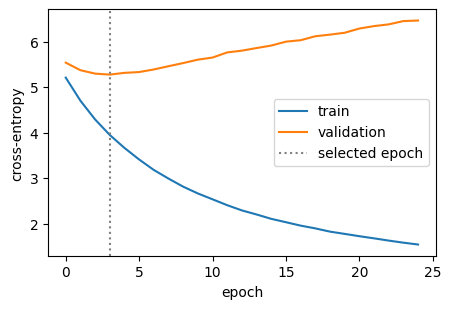

In [6]:
loss_fn = nn.CrossEntropyLoss()

def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        return loss_fn(model(X), y).item()

def fit(model, X_tr, y_tr, X_va, y_va, n_epochs=25, learning_rate=3e-3, batch_size=128, seed=0):
    torch.manual_seed(seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = {"train": [], "val": []}
    best_loss, best_state = float("inf"), None
    for epoch in range(n_epochs):
        model.train()
        order = torch.randperm(len(X_tr))
        for start in range(0, len(order), batch_size):
            batch = order[start:start + batch_size]
            optimizer.zero_grad()
            loss_fn(model(X_tr[batch]), y_tr[batch]).backward()
            optimizer.step()
        history["train"].append(evaluate(model, X_tr, y_tr))
        history["val"].append(evaluate(model, X_va, y_va))
        if history["val"][-1] < best_loss:
            best_loss = history["val"][-1]
            best_state = {name: value.clone() for name, value in model.state_dict().items()}
            history["best_epoch"] = epoch
    model.load_state_dict(best_state)
    return model, history

torch.manual_seed(0)
rnn, hist_rnn = fit(NextWordNet(VOCAB_SIZE, kind="rnn"), X_train, y_train, X_val, y_val)

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(hist_rnn["train"], label="train")
ax.plot(hist_rnn["val"], label="validation")
ax.axvline(hist_rnn["best_epoch"], color="gray", linestyle=":", label="selected epoch")
ax.set(xlabel="epoch", ylabel="cross-entropy")
ax.legend()
plt.show()

The training loss keeps falling (to about 1.5 after 25 epochs) while the validation loss is lowest after only 4 epochs and then rises: the network memorizes the book. Early stopping returns the weights of the 4th epoch. This is the central problem of this chapter: the book is tiny compared with the number of parameters.

### Baselines: Unigram and Bigram

To judge the number we need simple reference models, estimated on the same training segment and evaluated on the same test examples (same targets):

- **unigram**: the next word is drawn from the overall word frequencies, ignoring the context;
- **bigram**: the next word depends only on the previous word, $P(w_{t+1} \mid w_t)$, estimated from counts (the model of the [bigram chapter](03-02-ANN-Bigram-Motivation.ipynb)). Because many pairs never occur in the training text we add a small constant $\alpha$ to every count (additive smoothing), otherwise unseen pairs would get probability zero and an infinite loss. We choose $\alpha$ on the validation set, so that the baseline is not handicapped by a poor choice.

In [7]:
train_ids = segments["train"]
pair_counts = np.zeros((VOCAB_SIZE, VOCAB_SIZE))
np.add.at(pair_counts, (train_ids[:-1], train_ids[1:]), 1)

def smoothed_bigram(alpha):
    counts_ = pair_counts + alpha
    return counts_ / counts_.sum(axis=1, keepdims=True)

def baseline_cross_entropy(probs_for, X, y):
    return -np.mean(np.log(probs_for(X)[np.arange(len(y)), y.numpy()]))

# choose the smoothing constant on the validation set
alphas = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]
val_ce = [baseline_cross_entropy(lambda X: smoothed_bigram(a)[X[:, -1].numpy()], X_val, y_val) for a in alphas]
ALPHA = alphas[int(np.argmin(val_ce))]
print("validation cross-entropy of the bigram model for alpha =", dict(zip(alphas, np.round(val_ce, 3))))
print("chosen alpha:", ALPHA)

bigram_probs = smoothed_bigram(ALPHA)
unigram_counts = np.bincount(train_ids, minlength=VOCAB_SIZE) + ALPHA
unigram_probs = unigram_counts / unigram_counts.sum()

ce_unigram = baseline_cross_entropy(lambda X: np.tile(unigram_probs, (len(X), 1)), X_test, y_test)
ce_bigram = baseline_cross_entropy(lambda X: bigram_probs[X[:, -1].numpy()], X_test, y_test)
ce_rnn = evaluate(rnn, X_test, y_test)

def top_k_accuracy(scores, y, k):
    top = np.argsort(-scores, axis=1)[:, :k]
    return (top == y.numpy()[:, None]).any(axis=1).mean()

with torch.no_grad():
    rnn.eval()
    rnn_scores = rnn(X_test).numpy()
bigram_scores = bigram_probs[X_test[:, -1].numpy()]

print(f"{'model':<10} {'test CE':>8} {'perplexity':>11} {'top-1':>7} {'top-5':>7}")
for name, ce, scores in [("unigram", ce_unigram, np.tile(unigram_probs, (len(X_test), 1))),
                         ("bigram", ce_bigram, bigram_scores),
                         ("RNN", ce_rnn, rnn_scores)]:
    print(f"{name:<10} {ce:>8.3f} {np.exp(ce):>11.1f} {top_k_accuracy(scores, y_test, 1):>7.3f} {top_k_accuracy(scores, y_test, 5):>7.3f}")

validation cross-entropy of the bigram model for alpha = {0.001: np.float64(6.018), 0.003: np.float64(5.734), 0.01: np.float64(5.534), 0.03: np.float64(5.486), 0.1: np.float64(5.6), 0.3: np.float64(5.849)}
chosen alpha: 0.03
model       test CE  perplexity   top-1   top-5
unigram       5.995       401.2   0.080   0.220
bigram        5.625       277.3   0.157   0.311


RNN           5.381       217.3   0.142   0.323


The RNN has the lowest cross-entropy and perplexity: about 217 against 277 for the bigram model and 401 for the unigram model (a perplexity of 217 still means that the model is as uncertain as if it chose between 217 equally likely words, so predicting the next word of a novel remains hard). The picture is more mixed for the accuracy: the RNN is *less* often right with its first guess than the bigram model (14.2% vs. 15.7%) but slightly more often right within its first five guesses (32.3% vs. 31.1%). Perplexity rewards the probability assigned to the right word even when it is not the top choice, which makes it the better measure here.

### Gated Variants

The simple recurrent cell multiplies by $W_h$ and applies $\tanh$ at every step, so the influence of early words on the state (and on the gradient) tends to fade quickly for long sequences (the *vanishing gradient* problem). The **GRU** [@CHO2014LearningPhraseRepresentations] and **LSTM** [@HOCHREITER1997LongShortTermMemory] add *gates*: learned numbers between 0 and 1 that decide how much of the old state to keep and how much of the new input to write. We simply swap the layer and compare.

In [8]:
results = {"rnn": (rnn, hist_rnn)}
for kind in ["gru", "lstm"]:
    torch.manual_seed(0)
    results[kind] = fit(NextWordNet(VOCAB_SIZE, kind=kind), X_train, y_train, X_val, y_val)

print(f"{'layer':<6} {'parameters':>11} {'best epoch':>11} {'val perplexity':>15} {'test perplexity':>16}")
for kind, (model, history) in results.items():
    print(f"{kind:<6} {count_parameters(model):>11} {history['best_epoch'] + 1:>11} "
          f"{np.exp(min(history['val'])):>15.1f} {np.exp(evaluate(model, X_test, y_test)):>16.1f}")

layer   parameters  best epoch  val perplexity  test perplexity
rnn         275921           4           196.2            217.3
gru         317393           4           174.2            196.1
lstm        338129           5           169.6            191.2


The gated cells are better on the validation and test sets (perplexity 196 for the GRU and 191 for the LSTM, against 217 for the simple RNN) at the price of more parameters (317,393 and 338,129 against 275,921). All three overfit after 4-5 epochs.

## What Can We Do with a Next-Word Model?

### 1. Next-Word Suggestions

The most direct use is *autocomplete*: show the most probable continuations of what the user has typed. The network accepts a prompt of any length. We never suggest `<unk>`.

In [9]:
def next_word_probs(model, words):
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor([encode(words)]))[0]
    logits[UNK] = float("-inf")
    return torch.softmax(logits, dim=0)

def suggest(model, prompt, k=5):
    probs = next_word_probs(model, prompt.lower().split())
    top = torch.topk(probs, k)
    return ", ".join(f"{vocabulary[i]} ({p:.2f})" for p, i in zip(top.values, top.indices))

for prompt in ["alice was beginning to get very", "she went on and", "the queen of", "off with her", "said the mock"]:
    print(f"{prompt!r:<40} -> {suggest(rnn, prompt)}")

'alice was beginning to get very'        -> likely (0.04), much (0.03), glad (0.03), tired (0.02), carefully (0.02)
'she went on and'                        -> began (0.05), looked (0.04), the (0.03), said (0.03), alice (0.02)
'the queen of'                           -> hearts (0.07), the (0.06), course (0.03), its (0.02), mercia (0.02)
'off with her'                           -> head (0.24), knowledge (0.03), flamingo (0.03), life (0.03), face (0.02)
'said the mock'                          -> turtle (0.95), voice (0.00), little (0.00), rabbit (0.00), head (0.00)


Some suggestions are impressively specific: after "off with her" the model expects "head" (probability 0.24, the Queen's famous sentence), after "the queen of" it expects "hearts", and after "said the mock" it is almost certain about "turtle" (0.95). Because the network has memorized parts of the book these are partly *recollections*, not understanding. Other suggestions are only plausible: after "alice was beginning to get very" the model spreads its probability over several words, none above 0.04.

### 2. The Context Matters

A bigram model gives the same answer after "the" whatever came before. The recurrent network does not.

In [10]:
# no-ex-class
bigram_top = np.argsort(-bigram_probs[word_to_id["the"]])[1:6]   # skip <unk>, which is index 0
print("bigram, after 'the' (always the same):", ", ".join(vocabulary[i] for i in bigram_top))
print()
for prompt in ["alice looked at the", "the queen shouted at the", "she jumped down the", "once upon a time the"]:
    print(f"RNN {prompt!r:<30} -> {suggest(rnn, prompt)}")

bigram, after 'the' (always the same): queen, mock, duchess, hatter, gryphon

RNN 'alice looked at the'          -> bottom (0.05), other (0.05), king (0.04), queen (0.04), door (0.03)
RNN 'the queen shouted at the'     -> bottom (0.10), other (0.05), march (0.03), door (0.03), end (0.03)
RNN 'she jumped down the'          -> queen (0.13), hatter (0.04), mouse (0.04), march (0.03), rabbit (0.03)
RNN 'once upon a time the'         -> queen (0.12), little (0.05), mouse (0.03), rabbit (0.03), game (0.02)


How much does a longer context help on the test set? We retrain the network with contexts of length $L = 1, 2, 4, 8$ and compare the test perplexity (always on the same test targets). With $L = 1$ the network sees the same information as the bigram model.

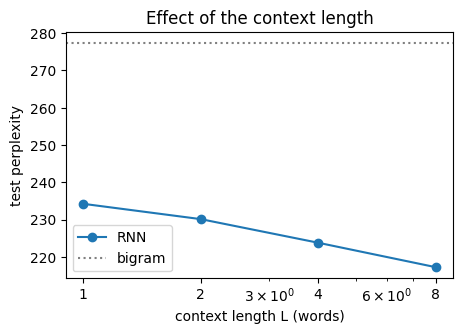

{1: np.float64(234.2), 2: np.float64(230.1), 4: np.float64(223.8), 8: np.float64(217.3)}


In [11]:
# no-ex-class
context_results = {}
for context in [1, 2, 4, 8]:
    Xtr, ytr = make_windows(segments["train"], context)
    Xva, yva = make_windows(segments["val"], context)
    Xte, yte = make_windows(segments["test"], context)
    torch.manual_seed(0)
    model, _ = fit(NextWordNet(VOCAB_SIZE, kind="rnn"), Xtr, ytr, Xva, yva)
    context_results[context] = np.exp(evaluate(model, Xte, yte))

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(list(context_results), list(context_results.values()), marker="o", label="RNN")
ax.axhline(np.exp(ce_bigram), color="gray", linestyle=":", label="bigram")
ax.set(xlabel="context length L (words)", ylabel="test perplexity", xscale="log", xticks=[1, 2, 4, 8], title="Effect of the context length")
ax.set_xticklabels([1, 2, 4, 8])
ax.legend()
plt.show()
print({context: round(value, 1) for context, value in context_results.items()})

The suggestions depend on the whole prompt, not only on the last word, but the differences are modest and not always sensible: "alice looked at the" and "the queen shouted at the" both lead to "bottom", and "she jumped down the" is followed by "queen". The model has learned some context effects, but it is not accurate with only 22,000 words of training text.

The table shows the typical gain from a longer context: the test perplexity falls from 234 with one word of context to 230, 224 and 217 with 2, 4 and 8 words. Two remarks. First, the effect of the context is real but small: most of the improvement over the bigram model (perplexity 277) is already present with $L = 1$, where the RNN sees the same information. It comes from the embeddings, which let the model share information between similar words, instead of treating every pair of words separately, and from the regularization. Second, a larger gain from longer contexts would require much more training data.

### 3. Text Generation

A language model can write text: predict the distribution of the next word, **sample** a word from it, append it to the text and repeat. The **temperature** $\tau$ controls the randomness: the logits are divided by $\tau$ before the softmax. A low temperature concentrates the probability on the most likely words (at $\tau \to 0$ we always take the most probable word), a high temperature flattens the distribution and produces more surprising (and more erroneous) text.

In [12]:
def generate(model, prompt, n_words=25, temperature=1.0, seed=0, context=CONTEXT):
    generator = torch.Generator().manual_seed(seed)
    words = prompt.lower().split()
    model.eval()
    for _ in range(n_words):
        with torch.no_grad():
            logits = model(torch.tensor([encode(words[-context:])]))[0]
        logits[UNK] = float("-inf")
        if temperature == 0:
            next_id = logits.argmax().item()
        else:
            next_id = torch.multinomial(torch.softmax(logits / temperature, dim=0), 1, generator=generator).item()
        words.append(vocabulary[next_id])
    return " ".join(words)

def generate_bigram(prompt, n_words=25, seed=0):
    generator = np.random.default_rng(seed)
    words = prompt.lower().split()
    for _ in range(n_words):
        probs = bigram_probs[word_to_id.get(words[-1], UNK)].copy()
        probs[UNK] = 0
        words.append(vocabulary[generator.choice(VOCAB_SIZE, p=probs / probs.sum())])
    return " ".join(words)

prompt = "alice was beginning to get very"
print("bigram           :", generate_bigram(prompt))
print("RNN, greedy      :", generate(rnn, prompt, temperature=0))
for temperature in [0.5, 1.0, 1.5]:
    print(f"RNN, tau = {temperature:<4}  :", generate(rnn, prompt, temperature=temperature))

bigram           : alice was beginning to get very uncomfortable queer it ' 'how line caucus panther twinkling painting law and whispered for instantly question 'nobody crowd hard moral of the answer sorts gently
RNN, greedy      : alice was beginning to get very likely to be a little thing and she was a good deal of the queen of the house to the game of the house to
RNN, tau = 0.5   : alice was beginning to get very way of the house to herself that you and ' said the mock turtle sighed her head as she could not could not like here
RNN, tau = 1.0   : alice was beginning to get very way trying that up had to bring you and ' 'no still with the end in a understand nurse 'off to stand did ' for
RNN, tau = 1.5   : alice was beginning to get very way trying bear up had made bring you and ' 'no still 'one loudly round stop indeed came painting 'off 'you're sobs or some for


Greedy decoding (always the most probable word) produces fluent but repetitive text ("of the house to the game of the house to ..."): the same words keep being the most probable ones. With a temperature of 0.5 the text looks like Alice in Wonderland in places ("said the mock turtle sighed her head") but makes little sense; at $\tau = 1$ and $\tau = 1.5$ it becomes a mixture of unrelated words, similar to the text sampled from the bigram model. This is not surprising for a network that has seen 22,000 words. The mechanism is the same as in large language models, only the quality of the probabilities differs.

### 4. Scoring Sentences

The probability that the model assigns to a text measures how *natural* the text is: $\log P(w_1, \ldots, w_n) = \sum_{t} \log P(w_t \mid w_1, \ldots, w_{t-1})$. We use the **perplexity per word** (the exponential of the average negative log-probability) so that texts of different length are comparable. Possible applications are detecting unnatural or machine-generated text, ranking candidate translations or speech-recognition outputs, and spotting typos.

As a test we take 12-word excerpts from the **test** part of the book and compare each one with the same words in a random order. A good model should find the original much more probable.

In [13]:
def sentence_perplexity(model, words):
    # perplexity per word; the first word has no context and is not scored
    model.eval()
    ids_ = torch.tensor([encode(words)])
    log_probs = []
    for t in range(1, len(words)):
        with torch.no_grad():
            logits = model(ids_[:, :t])[0]
        log_probs.append(torch.log_softmax(logits, dim=0)[ids_[0, t]].item())
    return float(np.exp(-np.mean(log_probs)))

test_words = [vocabulary[i] for i in segments["test"]]
rng = np.random.default_rng(0)
original, shuffled = [], []
for start in range(0, len(test_words) - 12, 12):
    excerpt = test_words[start:start + 12]
    if "<unk>" in excerpt:
        continue
    original.append(sentence_perplexity(rnn, excerpt))
    shuffled.append(sentence_perplexity(rnn, list(rng.permutation(excerpt))))

original, shuffled = np.array(original), np.array(shuffled)
print("excerpts:", len(original))
print(f"median perplexity per word: original {np.median(original):.0f}, shuffled {np.median(shuffled):.0f}")
print(f"original text has the lower perplexity in {(original < shuffled).mean():.0%} of the excerpts")

excerpts: 125
median perplexity per word: original 285, shuffled 1227
original text has the lower perplexity in 98% of the excerpts


In [14]:
# no-ex-class
examples = ["alice was very tired of sitting by her sister on the bank",
            "alice was bank very her of tired sitting sister by the on",
            "the queen said off with her head to the king",
            "the queen said her with off head king the to"]
for sentence in examples:
    print(f"{sentence_perplexity(rnn, sentence.split()):>8.0f}  {sentence}")

      54  alice was very tired of sitting by her sister on the bank
    1230  alice was bank very her of tired sitting sister by the on
      37  the queen said off with her head to the king
     365  the queen said her with off head king the to


The model clearly prefers the original word order: the median perplexity per word is 285 for the original excerpts and 1227 for the shuffled ones, and the original has the lower perplexity in 98% of the 125 excerpts. In the examples the natural sentences get perplexities of 54 and 37, the scrambled ones 1230 and 365. The same principle is used in practice to rank alternative outputs of speech recognition and translation systems. Note that the score depends on the training corpus: a perfectly good sentence about a topic that does not occur in *Alice in Wonderland* would also get a high perplexity.

### 5. What Did the Embeddings Learn?

The embedding matrix is learned as part of the network. Words that are used in similar contexts should get similar vectors. We list the nearest neighbours (by cosine similarity) of a few words; compare with the [Word2Vec chapter](03-09-Word2Vec.ipynb), where the same idea was the entire goal of the model.

In [15]:
# no-ex-class
embedding_matrix = rnn.embedding.weight.detach()
normalized = embedding_matrix / embedding_matrix.norm(dim=1, keepdim=True)

def neighbours(word, k=6):
    similarity = normalized @ normalized[word_to_id[word]]
    top = torch.topk(similarity, k + 1).indices[1:]
    return ", ".join(vocabulary[i] for i in top)

for word in ["alice", "queen", "said", "little", "she", "very"]:
    print(f"{word:<8} -> {neighbours(word)}")

alice    -> five, guests, rabbit, adventures, 'yes, you
queen    -> procession, rude, 'which, animals, happened, worth
said     -> through, quarrelling, william, better, decidedly, putting
little   -> brightened, ring, politely, father, ran, let's
she      -> ever, sister, throwing, green, quickly, race
very     -> were, scream, catching, salt, hurried, means


The neighbours are essentially arbitrary: "queen" is not close to "king" or "duchess" and "said" is not close to other verbs of speaking. With 22,000 words and a model whose only job is to guess the next word the embeddings have not learned a useful geometry. Word2Vec trained on a corpus that is thousands of times larger, or pre-trained embeddings (see [Using Word Embeddings](04-01-Using-Word-Embeddings.ipynb)), would give meaningful neighbours. This is a useful reminder that what a network learns depends on the amount of data as much as on the architecture.

## Limitations

- **Tiny corpus.** About 22,000 training words are far too few for 276,000 parameters: the network memorizes the book after a few epochs (see the learning curves), and its predictions often reproduce sentences of the book. Real language models are trained on billions of words.
- **Word-level vocabulary.** Words outside the vocabulary become `<unk>`; character-level or sub-word models avoid this.
- **Fixed-size memory.** The whole past has to be squeezed into the state $h_t$ (128 numbers), and early words fade even with gated cells. Long-range dependencies are hard.
- **Sequential computation.** Step $t$ needs step $t-1$, so the computation cannot be parallelized over time. Transformers [@VASWANI2017AttentionAllYou] replace the recurrence by attention over all previous words (see the [positional encodings chapter](07-01-Positional-Encodings.ipynb)).

## Summary

- An RNN reads a sequence word by word and keeps a hidden state; the same weights are used at every step, so the number of parameters does not depend on the length of the text.
- Trained with the cross-entropy loss, the network gives a distribution over the next word given **all** previous words.
- Perplexity is the standard measure of a language model; we compared it with the unigram and bigram models.
- The same model can be used for suggestions, text generation (with a temperature) and scoring how natural a text is.

## Exercises

1. Change the hidden size (16, 64, 256) and the embedding size. When does the model start to overfit?
2. Train for more epochs without early stopping and generate text again. What do you notice?
3. Use only words with at least 5 occurrences. How do the vocabulary size, the perplexity and the share of `<unk>` change? Is perplexity comparable between the two vocabularies?
4. Implement a character-level model on the same text.
5. Replace `states[:, -1]` by the average of all states over time. What changes?